In [27]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict, GridSearchCV
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve

In [2]:
cars_train = pd.read_csv(Path('data/train.csv'))
cars_test = pd.read_csv(Path('data/test.csv'))

### Data analysis

In [3]:
cars_train.head(10)

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
5,5,50,95938.0,55.1,2,8,15,3.0,Other,Urban,Sedan,No,No,Low,No
6,6,55,109219.0,42.9,1,1,5,4.0,Male,Suburban,Sedan,Yes,Yes,Low,Yes
7,7,45,60796.0,52.2,2,13,3,2.0,Other,Urban,SUV,No,Yes,Medium,No
8,8,39,67725.0,31.5,2,11,3,2.0,Female,Urban,Sedan,No,Yes,Medium,No
9,9,57,114827.0,66.9,2,0,1,5.0,Male,Rural,Sedan,Yes,Yes,Low,Yes


In [4]:
cars_train.shape

(668665, 15)

In [5]:
cars_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

In [6]:
cars_train.describe()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,334332.000000,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,193027.103211,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,0.000000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,167166.000000,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,334332.000000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,501498.000000,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,668664.000000,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


Provided dataset is fully filled with data so there is no need to think about ways to fill in blank spaces. Additionally, id column could be removed since index consist of the same numbers. Set also include 7 columns with non-numerical attributes that shoud be checked to conclude the best ways of transformation.

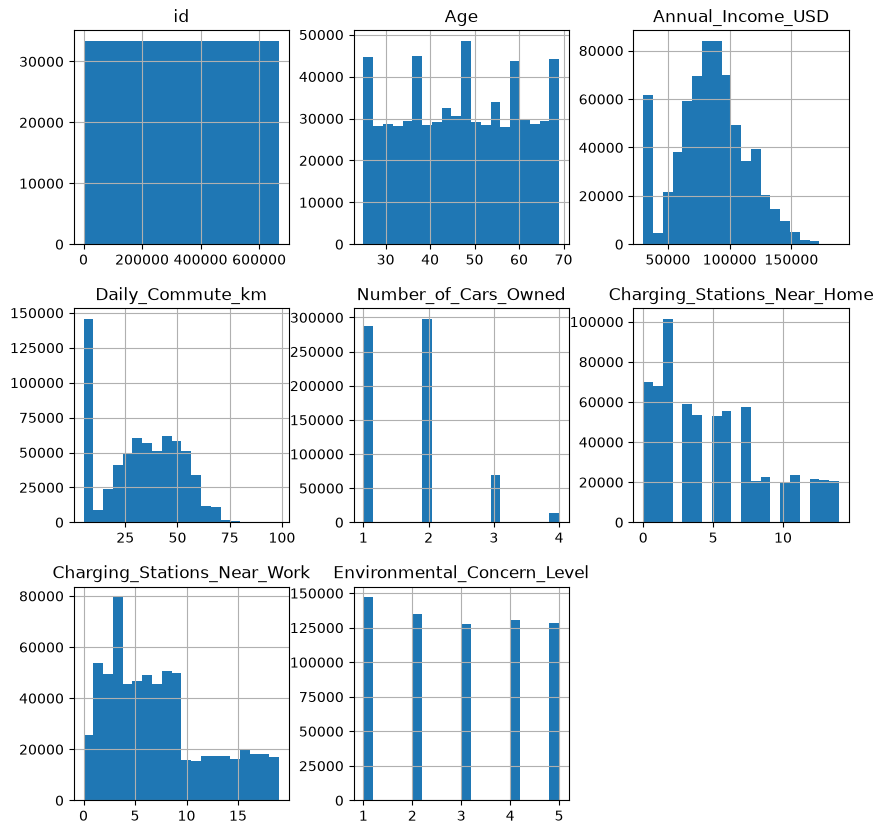

In [7]:
cars_train.hist(bins=20, figsize=(10,10))
plt.show()

Provided data is mostly equally distributed with exception of some right skewed attributes.

<Axes: >

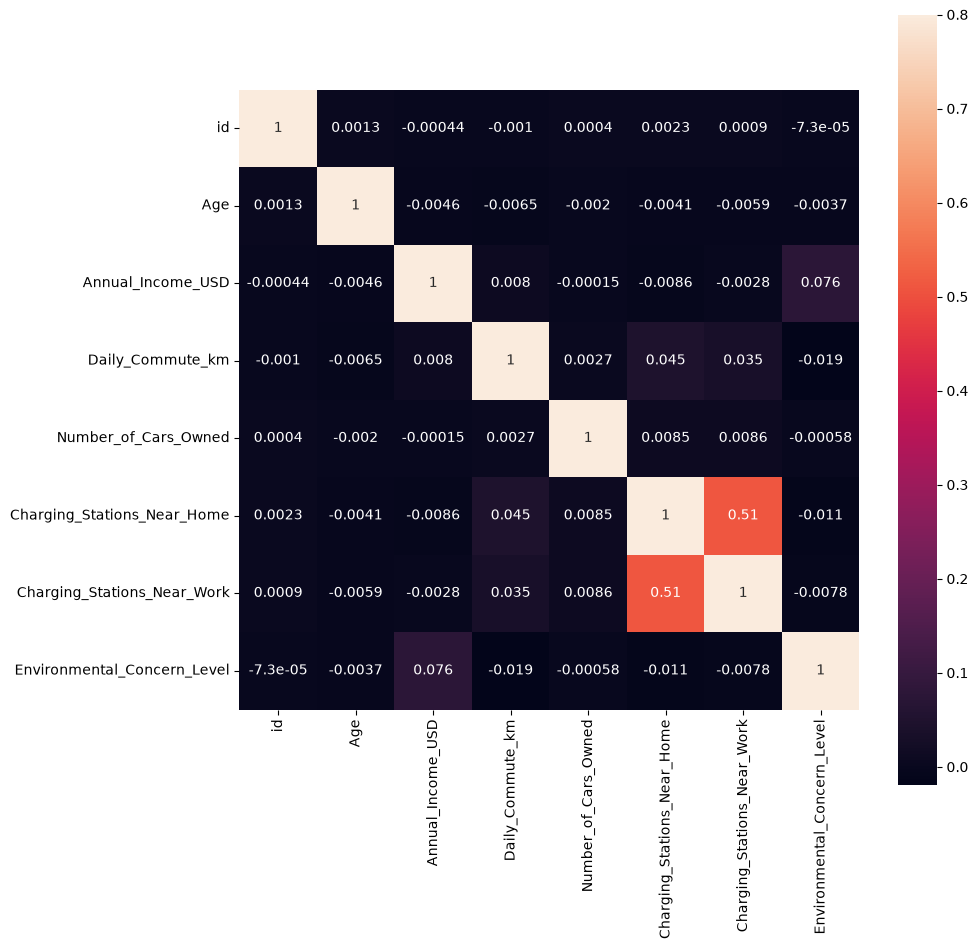

In [8]:
corrmat = cars_train.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(10,10))
sns.heatmap(corrmat, vmax=.8, square=True, annot=True)

Heatmap does not reveal any special relationships between numerical features. The only exception is correlation between 'Charging_Stations_Near_Work' and 'Charging_Stations_Near_Home'. For now there is no point in further examination of numerical attributes and in that case it is time to check text attributes. As stated before dataset included only 7 str columns so it is reasonable to take a look at most of them.

In [9]:
cars_train['Gender'].unique()

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

In [10]:
cars_train['City_Type'].unique()

<StringArray>
['Suburban', 'Rural', 'Urban']
Length: 3, dtype: str

In [11]:
cars_train['Current_Car_Type'].unique()

<StringArray>
['Sedan', 'SUV', 'Hatchback', 'Truck']
Length: 4, dtype: str

In [12]:
cars_train['Home_Charging_Possible'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [13]:
cars_train['Subsidy_Available'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [14]:
cars_train['Range_Anxiety_Level'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

In [15]:
cars_train['Will_Buy_EV'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Most text data only include two attributes so usage of OneHotEncoder seems to be simplest and best method. With this knowledge a copy of dataset with basic transformation can be made to get more information about dataset.

In [16]:
train_copy = cars_train.copy()
ct = ColumnTransformer(
    [('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), make_column_selector(dtype_include=object))],
    remainder='passthrough'
).set_output(transform="pandas")
copy_transformed = ct.fit_transform(train_copy)

In [17]:
copy_transformed.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 27 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   cat__Gender_Female                      668665 non-null  float64
 1   cat__Gender_Male                        668665 non-null  float64
 2   cat__Gender_Other                       668665 non-null  float64
 3   cat__City_Type_Rural                    668665 non-null  float64
 4   cat__City_Type_Suburban                 668665 non-null  float64
 5   cat__City_Type_Urban                    668665 non-null  float64
 6   cat__Current_Car_Type_Hatchback         668665 non-null  float64
 7   cat__Current_Car_Type_SUV               668665 non-null  float64
 8   cat__Current_Car_Type_Sedan             668665 non-null  float64
 9   cat__Current_Car_Type_Truck             668665 non-null  float64
 10  cat__Home_Charging_Possible_No          668665 non-null

<Axes: >

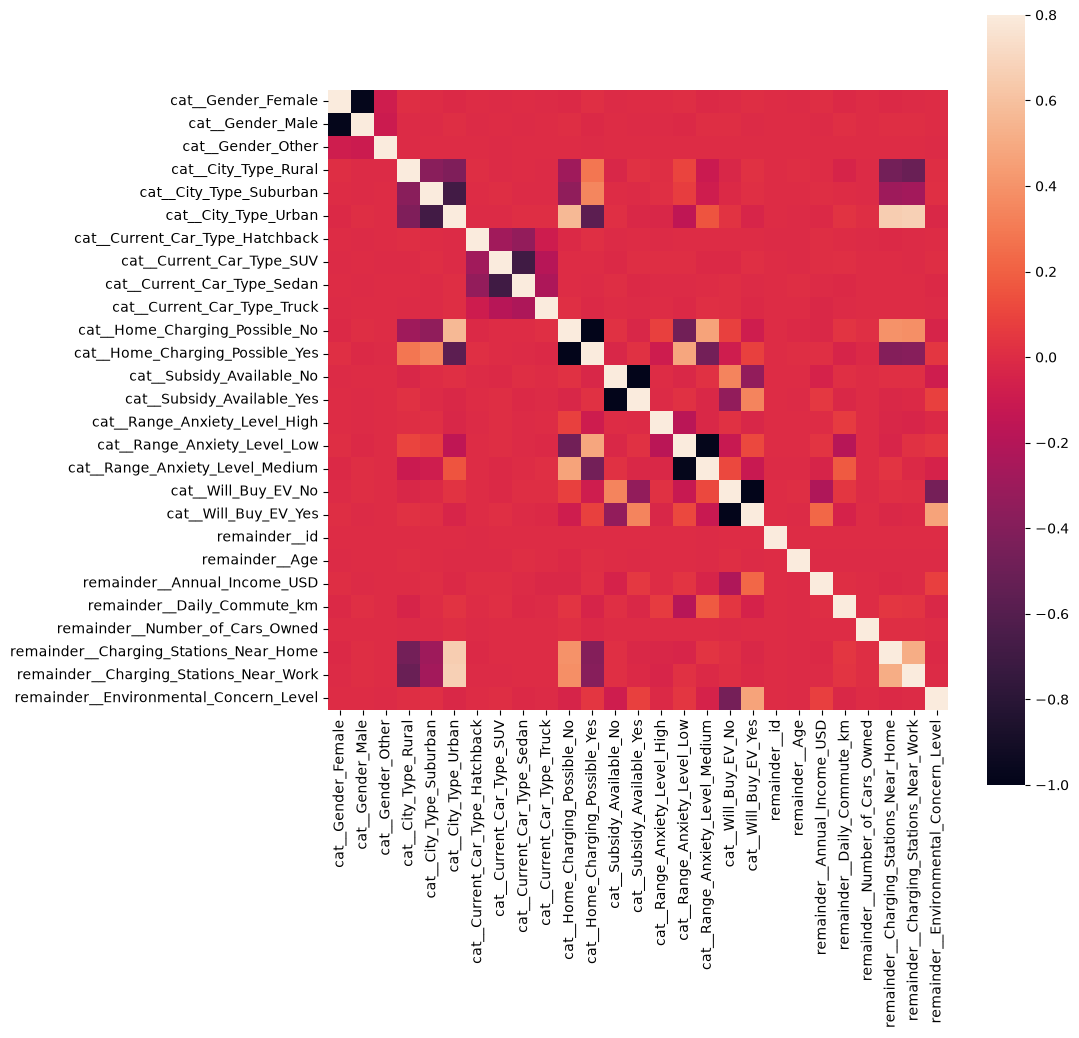

In [18]:
corrmat = copy_transformed.corr()
f, ax = plt.subplots(figsize=(10,10))
sns.heatmap(corrmat, vmax=.8, square=True, annot=False)

In [19]:
corr_matrix = copy_transformed.corr()
corr_matrix['cat__Will_Buy_EV_Yes'].sort_values(ascending=False)

cat__Will_Buy_EV_Yes                      1.000000
remainder__Environmental_Concern_Level    0.464079
cat__Subsidy_Available_Yes                0.342382
remainder__Annual_Income_USD              0.225729
cat__Range_Anxiety_Level_Low              0.115744
cat__Home_Charging_Possible_Yes           0.083584
cat__City_Type_Rural                      0.023555
cat__City_Type_Suburban                   0.013026
cat__Current_Car_Type_SUV                 0.012697
cat__Gender_Female                        0.007021
remainder__Number_of_Cars_Owned           0.003896
remainder__id                            -0.000013
cat__Gender_Other                        -0.000215
cat__Current_Car_Type_Hatchback          -0.000334
cat__Current_Car_Type_Sedan              -0.006429
cat__Gender_Male                         -0.006971
remainder__Age                           -0.007450
cat__Current_Car_Type_Truck              -0.011987
remainder__Charging_Stations_Near_Work   -0.012229
remainder__Charging_Stations_Ne

Both heatmap and correlation matrix show more relationships between data. It is visible that there is some 'excluding' yes/no data, but it is still visible that customers with environmental concern level and available spare car are more inclined to buy ev.

### Creation of pipeline

Based on gather knowledge of data there is no need to create any complicated pipelines most importantly it should remove 'id' column, equally distribute numerical values and for text values apply OneHotEncoder except 'Will_Buy_EV' column which will be transformed with 0 representing 'no' and 1 for 'yes'. Additionally, it is worth to add missing data handling in case of any future lacking data.

In [20]:
y_train = cars_train['Will_Buy_EV'].copy()
cars_train.drop('Will_Buy_EV', axis=1, inplace=True)
y_train = y_train.map({'Yes': 1, 'No': 0})

cars_train = cars_train.set_index('id')

In [21]:
cat_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
    StandardScaler()
)

def drop_id_column(df):
    return df.drop(columns=['id'], errors='ignore')

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, make_column_selector(dtype_include=object)),
    ('num', num_pipeline, make_column_selector(dtype_include=np.number))
])

master_pipeline = Pipeline([
    ('drop_id', FunctionTransformer(drop_id_column)),
    ('preprocessor', preprocessor)
])

In [22]:
train_X = master_pipeline.fit_transform(cars_train)
train_X.shape


(668665, 24)

### Model training

To get a baseline for models, we will use DummyClassifier and get its score to provide a reference for our futer models and they skewness.

In [23]:
dummy_clf = DummyClassifier()
dummy_clf.fit(train_X, y_train)
dummy_pred = cross_val_predict(dummy_clf, train_X, y_train, cv=3)
print(confusion_matrix(dummy_pred, y_train))
f1_score(dummy_pred, y_train)

[[551886 116779]
 [     0      0]]


0.0

Unsurprisingly DummyClassifier isn't very good at prediction, for every given values it 'predicted' the most popular answear from the set which is 'no'. With that in mind it is time to try real classification models.

In [24]:
logreg_clf = LogisticRegression(class_weight='balanced', max_iter=1000)
logreg_clf.fit(train_X, y_train)
logreg_pred = cross_val_predict(logreg_clf, train_X, y_train, cv=3)
print(confusion_matrix(logreg_pred, y_train))
f1_score(logreg_pred, y_train)

[[458193   9628]
 [ 93693 107151]]


0.6747055471423669

In [25]:
sgd_clf = SGDClassifier(class_weight='balanced', random_state=42)
sgd_clf.fit(train_X, y_train)
sgd_pred = cross_val_predict(sgd_clf, train_X, y_train, cv=3)
print(confusion_matrix(sgd_pred, y_train))
f1_score(sgd_pred, y_train)

[[450727   8558]
 [101159 108221]]


0.6636088533506664

In [26]:
forest_clf = RandomForestClassifier(class_weight='balanced', random_state=42)
forest_clf.fit(train_X, y_train)
forest_pred = cross_val_predict(forest_clf, train_X, y_train, cv=3)
print(confusion_matrix(forest_pred, y_train))
f1_score(forest_pred, y_train)

[[496059  23535]
 [ 55827  93244]]


0.7014782772239985